# Demo: Neural SSM Comparison on Synthetic Data

This notebook is organized as a presentation-style walkthrough comparing **DiscreteSSM**, **ODESSM**, and **SDESSM** on a shared synthetic benchmark.

- Latent process: Lorenz-96 dynamics with time-varying diffusion
- Observation process: linear emission into a higher-dimensional noisy observation space
- Main evaluation focus: observed trajectories, including context fit and forecast
- Latent-state identifiability is discussed separately in the final remark section

**[NOTE]** We did not heavily tune any of the models; instead, the hyperparameters were chosen somewhat heuristically based on experience with the ballpark values that typically start to work, and the total number of training epochs was set to either 50 or 100 depending on the model.

In [1]:
from pathlib import Path
import os, sys

repo_root = Path.cwd()
if repo_root.name == 'demo':
    repo_root = repo_root.parent
os.chdir(repo_root)
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
torch.set_float32_matmul_precision('high')
from torch.utils.data import DataLoader

from demo.eval import (
    forecast_from_trajectory,
    infer_context_latent_from_trajectory,
    reconstruct_context_plus_one_from_trajectory,
    reconstruct_context_same_grid_from_trajectory,
)
from demo.lorenz96 import SimLorenz
from src.data.dataset_ssm import TSDataset
from src.data.utils import prepare_batched_traj
from src.models import (
    DiscreteSSM, DiscreteModelConfig, DiscreteOptConfig,
    ODESSM, ODEModelConfig, ODEOptConfig,
    SDESSM, SDEModelConfig, SDEOptConfig,
)
from src.models.ode.network import LatentODEModel
from src.utils.trainer import configure_trainer

%matplotlib inline


In [3]:
SEED = 123
GPU_ID = 0
NUM_WORKERS = 4
BATCH_SIZE = 128

OBS_DIMS_TO_PLOT = [0, 15, 29]
LATENT_DIMS_TO_PLOT = [0, 1, 2]
SNAPSHOT_SLICE = slice(0, 800)

PLOT_COLORS = {
    'ctx_truth': '#8A8A8A',
    'ctx_fit_same_grid': '#00A087',
    'ctx_fit_plus_one': '#E64B35',
    'future_truth': '#8A8A8A',
    'forecast': '#3C5488',
    'latent_true': '#8A8A8A',
    'latent_ctx': '#00A087',
    'latent_forecast': '#3C5488',
    'grid': '#BDBDBD',
}

np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device(f'cuda:{GPU_ID}' if torch.cuda.is_available() else 'cpu')
OUTPUT_DIR = Path('output')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Generate Synthetic Data via `SimLorenz`

The synthetic data in this notebook are generated from a stochastic Lorenz-96 state-space model. The latent process is low-dimensional and nonlinear, while the observed data are higher-dimensional noisy linear mixtures of the latent states.

Let $z_k \in \mathbb{R}^p$ denote the latent state at time $t_k = k\Delta t$, where $p = 5$ and $\Delta t = 0.05$. The latent dynamics are simulated using an Euler-Maruyama discretization of a stochastic Lorenz-96 system:
$$
z_{k+1} = z_k + f_{\mathrm{L96}}(z_k)\Delta t + \sigma(t_k)\sqrt{\Delta t}\,\varepsilon_k,
\qquad
\varepsilon_k \sim \mathcal{N}(0, I_p).
$$

The Lorenz-96 drift is defined coordinate-wise as
$$
f_i(z) = (z_{i+1} - z_{i-2})z_{i-1} - z_i + F,
$$
with cyclic indexing and forcing parameter $F = 2.8$. Hence, each latent coordinate depends on itself and a small local neighborhood of coordinates, producing nonlinear coupled dynamics.

The diffusion is additive and state-independent, but varies over time and across latent coordinates:
$$
\sigma_i(t) = \operatorname{clip}\!\left(\sigma_0\bigl[1 + \rho \sin(\omega t + \phi_i)\bigr], \sigma_{\min}, \sigma_{\max}\right).
$$
In the demo, the parameters are
$$
\sigma_0 = 0.10, \qquad \rho = 0.15, \qquad \omega = 0.15, \qquad \sigma_{\min} = 0.06, \qquad \sigma_{\max} = 0.14.
$$
The phase offsets $\phi_i$ are evenly spaced over $[0, 2\pi)$, which induces mild coordinate-specific oscillations in the latent noise scale.

The latent process is initialized from a small Gaussian perturbation,
$$
z_0 \sim \mathcal{N}(0, 0.01^2 I_p),
$$
and a burn-in period of $1000$ steps is discarded so that the retained trajectory is less sensitive to initialization and better reflects the long-run stochastic regime.

Observations $x_k \in \mathbb{R}^{d_x}$ with $d_x = 30$ are generated from the latent state through a linear Gaussian emission model:
$$
x_k = W z_k + b + \eta_k,
\qquad
\eta_k \sim \mathcal{N}(0, \sigma_{\mathrm{obs}}^2 I_{d_x}).
$$
In the demo, $\sigma_{\mathrm{obs}} = 0.15$ and $b = 0$. The emission matrix $W \in \mathbb{R}^{30 \times 5}$ is sampled randomly row-wise from a Gaussian distribution and each row is normalized to unit norm. Therefore, each observed variable is a noisy linear combination of the latent coordinates.

In this notebook, we generate one long trajectory of length $18000$ after burn-in. Overall, the dataset consists of high-dimensional noisy observations of a low-dimensional nonlinear stochastic dynamical system with time-varying latent diffusion.



In [4]:
LATENT_DIM = 5
OBS_DIM = 30
TOTAL_STEPS = 18000

SIM_CONFIG = {
    'force': 2.8,
    'delta_t': 0.05,
    'burn_in': 1000,
    'x0_scale': 0.01,
    'sigma0': 0.10,
    'sigma_rho': 0.15,
    'sigma_omega': 0.15,
    'sigma_min': 0.06,
    'sigma_max': 0.14,
    'obs_noise_scale': 0.15,
    'emission_scale': 1.0,
}

sim = SimLorenz(
    latent_dim=LATENT_DIM,
    obs_dim=OBS_DIM,
    seed=SEED,
    **SIM_CONFIG,
)

obs_np, latent_np, tps_np, emission_matrix = sim.sim_long_series_state_space(
    n_steps=TOTAL_STEPS,
    seed=SEED,
    return_emission_matrix=True,
)

print('obs shape   :', obs_np.shape)
print('latent shape:', latent_np.shape)
print('time shape  :', tps_np.shape)
print('emission W  :', emission_matrix.shape)


obs shape   : (18000, 30)
latent shape: (18000, 5)
time shape  : (18000,)
emission W  : (30, 5)


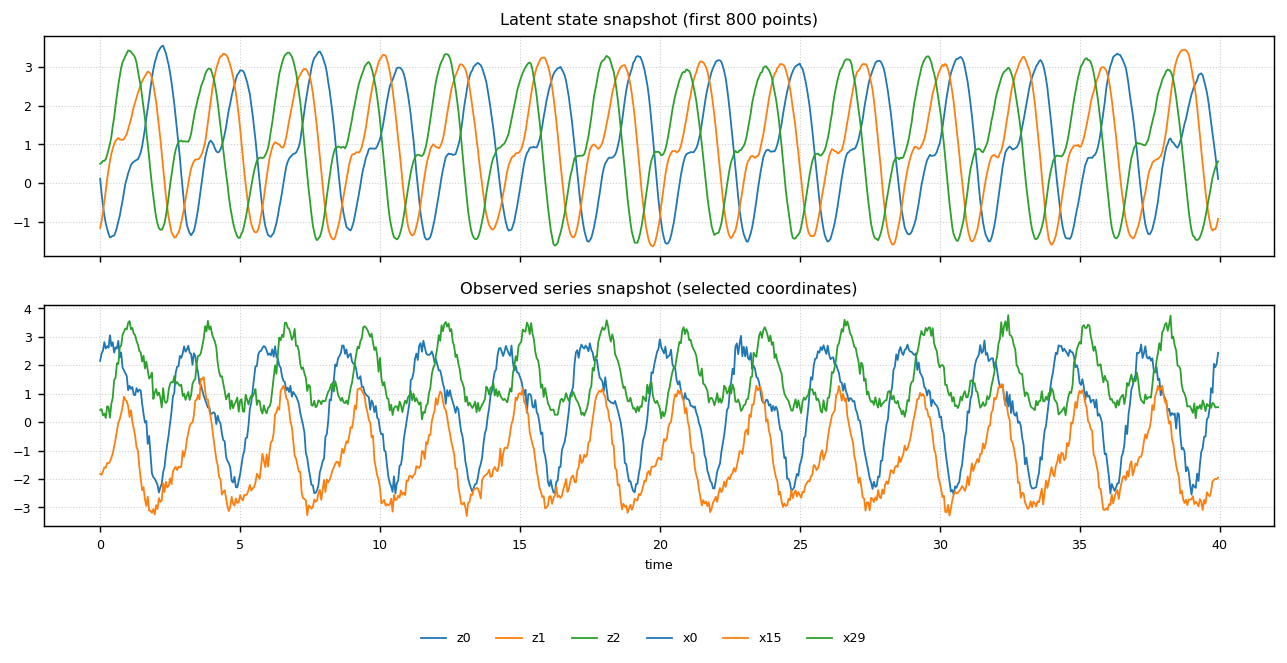

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5), dpi=130, sharex=True)
for d in LATENT_DIMS_TO_PLOT:
    axes[0].plot(tps_np[SNAPSHOT_SLICE], latent_np[SNAPSHOT_SLICE, d], lw=1.0, label=f'z{d}')
axes[0].set_title('Latent state snapshot (first 800 points)', fontsize=9)
axes[0].tick_params(axis='both', labelsize=7)
axes[0].grid(linestyle=':', linewidth=0.6, alpha=0.7, color=PLOT_COLORS['grid'])
for spine in axes[0].spines.values():
    spine.set_visible(True)
    spine.set_color('black')
    spine.set_linewidth(0.8)

for d in OBS_DIMS_TO_PLOT:
    axes[1].plot(tps_np[SNAPSHOT_SLICE], obs_np[SNAPSHOT_SLICE, d], lw=1.0, label=f'x{d}')
axes[1].set_title('Observed series snapshot (selected coordinates)', fontsize=9)
axes[1].tick_params(axis='both', labelsize=7)
axes[1].grid(linestyle=':', linewidth=0.6, alpha=0.7, color=PLOT_COLORS['grid'])
for spine in axes[1].spines.values():
    spine.set_visible(True)
    spine.set_color('black')
    spine.set_linewidth(0.8)
axes[1].set_xlabel('time', fontsize=7)
handles0, labels0 = axes[0].get_legend_handles_labels()
handles1, labels1 = axes[1].get_legend_handles_labels()
fig.legend(
    handles0 + handles1,
    labels0 + labels1,
    loc='lower center',
    bbox_to_anchor=(0.5, -0.02),
    ncol=6,
    fontsize=7,
    frameon=False,
)
plt.tight_layout(rect=(0, 0.08, 1, 1))


## 2. Basic Data Prep: Chronological Split, Normalization, and Windowing


In [6]:
CONTEXT_LEN = 80
PRED_LEN = 20
STRIDE_TRAIN = 5
STRIDE_EVAL = 10

TRAIN_FRACTION = 0.70
VAL_FRACTION = 0.15

n_train = int(TOTAL_STEPS * TRAIN_FRACTION)
n_val = int(TOTAL_STEPS * VAL_FRACTION)
n_test = TOTAL_STEPS - n_train - n_val

obs_train_raw = obs_np[:n_train]
obs_val_raw = obs_np[n_train:n_train + n_val]
obs_test_raw = obs_np[n_train + n_val:]

latent_train = latent_np[:n_train]
latent_val = latent_np[n_train:n_train + n_val]
latent_test = latent_np[n_train + n_val:]

delta_t = float(sim.delta_t)
t_train = np.arange(n_train, dtype=np.float32) * delta_t
t_val = np.arange(n_val, dtype=np.float32) * delta_t
t_test = np.arange(n_test, dtype=np.float32) * delta_t

mu = obs_train_raw.mean(axis=0, keepdims=True)
std = obs_train_raw.std(axis=0, keepdims=True) + 1e-6

obs_train = (obs_train_raw - mu) / std
obs_val = (obs_val_raw - mu) / std
obs_test = (obs_test_raw - mu) / std

train_df = pd.DataFrame(obs_train, index=t_train)
val_df = pd.DataFrame(obs_val, index=t_val)
test_df = pd.DataFrame(obs_test, index=t_test)

print('train/val/test lengths:', len(train_df), len(val_df), len(test_df))


train/val/test lengths: 12600 2700 2700


### Dataset Setup

Use `TSDataset` directly for the long observed and latent sequences where possible. For `ODESSM`, keep the original collate-time split/alignment behavior so the loader returns shared 1D timestamp grids.


In [7]:
ds_train = TSDataset(
    data=train_df,
    context_len=CONTEXT_LEN,
    pred_len=0,
    stride=STRIDE_TRAIN,
    relative_timestamps=True,
)
ds_val = TSDataset(
    data=val_df,
    context_len=CONTEXT_LEN,
    pred_len=PRED_LEN,
    stride=STRIDE_EVAL,
    relative_timestamps=True,
)
ds_test = TSDataset(
    data=test_df,
    context_len=CONTEXT_LEN,
    pred_len=PRED_LEN,
    stride=STRIDE_EVAL,
    relative_timestamps=True,
)

ode_ds_val = TSDataset(
    data=val_df,
    context_len=CONTEXT_LEN + PRED_LEN,
    pred_len=0,
    stride=STRIDE_EVAL,
    relative_timestamps=True,
)
ode_ds_test = TSDataset(
    data=test_df,
    context_len=CONTEXT_LEN + PRED_LEN,
    pred_len=0,
    stride=STRIDE_EVAL,
    relative_timestamps=True,
)

latent_ds_train = TSDataset(
    data=latent_train,
    context_len=CONTEXT_LEN,
    pred_len=0,
    stride=STRIDE_TRAIN,
    relative_timestamps=True,
)
latent_ds_test = TSDataset(
    data=latent_test,
    context_len=CONTEXT_LEN,
    pred_len=PRED_LEN,
    stride=STRIDE_EVAL,
    relative_timestamps=True,
)

print('dataset sizes (discrete/sde):', len(ds_train), len(ds_val), len(ds_test))
print('dataset sizes (ode full windows):', len(ds_train), len(ode_ds_val), len(ode_ds_test))
print('latent dataset sizes:', len(latent_ds_train), len(latent_ds_test))


dataset sizes (discrete/sde): 2505 261 261
dataset sizes (ode full windows): 2505 261 261
latent dataset sizes: 2505 261


### Model API Helpers

For `DiscreteSSM` and `SDESSM`, evaluation uses one dataset sample at a time. For `ODESSM`, training and validation keep the original collate-time shared-grid behavior, and the test visualization uses a collated batch with shared 1D timestamps.


In [8]:
def to_np(x):
    if isinstance(x, torch.Tensor):
        return x.detach().cpu().numpy()
    return np.asarray(x)


def sample_to_device(sample, device):
    return {
        key: value.to(device) if isinstance(value, torch.Tensor) else value
        for key, value in sample.items()
    }


def infer_context_latent_from_sample(lightning_module, sample):
    network = lightning_module.model
    return infer_context_latent_from_trajectory(
        network=network,
        x=sample['x_traj'],
        mask=sample['x_mask'],
        time_steps=sample['x_tps'],
    )


def reconstruct_context_from_sample(lightning_module, sample):
    network = lightning_module.model
    x_fit_same_grid, t_fit_same_grid = reconstruct_context_same_grid_from_trajectory(
        network=network,
        x=sample['x_traj'],
        mask=sample['x_mask'],
        time_steps=sample['x_tps'],
    )

    x_fit_plus_one = None
    t_fit_plus_one = None
    if not isinstance(network, LatentODEModel):
        x_fit_plus_one, t_fit_plus_one = reconstruct_context_plus_one_from_trajectory(
            network=network,
            x=sample['x_traj'],
            mask=sample['x_mask'],
            time_steps=sample['x_tps'],
        )

    return {
        'x_ctx_fit_same_grid': x_fit_same_grid,
        't_ctx_fit_same_grid': t_fit_same_grid,
        'x_ctx_fit_plus_one': x_fit_plus_one,
        't_ctx_fit_plus_one': t_fit_plus_one,
    }


def forecast_from_sample(lightning_module, sample):
    return forecast_from_trajectory(
        network=lightning_module.model,
        x=sample['x_traj'],
        mask=sample['x_mask'],
        time_steps=sample['x_tps'],
        time_steps_to_predict=sample['y_tps'],
        n_trajs=1,
    )


def evaluate_model_on_dataset_samples(lightning_module, obs_dataset, latent_dataset, n_plot=3):
    out = []
    n_samples = min(n_plot, len(obs_dataset), len(latent_dataset))

    with torch.no_grad():
        for idx in range(n_samples):
            obs_sample = sample_to_device(obs_dataset[idx], lightning_module.device)
            latent_sample = latent_dataset[idx]

            z_ctx = infer_context_latent_from_sample(lightning_module, obs_sample)
            ctx_fit = reconstruct_context_from_sample(lightning_module, obs_sample)
            x_pred, z_pred, t_pred = forecast_from_sample(lightning_module, obs_sample)

            out.append({
                'ctx_tps': to_np(obs_sample['x_tps']),
                'pred_tps': to_np(t_pred),
                'x_ctx_true': to_np(obs_sample['x_traj']),
                't_ctx_fit_same_grid': to_np(ctx_fit['t_ctx_fit_same_grid']),
                'x_ctx_fit_same_grid': to_np(ctx_fit['x_ctx_fit_same_grid']),
                't_ctx_fit_plus_one': None if ctx_fit['t_ctx_fit_plus_one'] is None else to_np(ctx_fit['t_ctx_fit_plus_one']),
                'x_ctx_fit_plus_one': None if ctx_fit['x_ctx_fit_plus_one'] is None else to_np(ctx_fit['x_ctx_fit_plus_one']),
                'x_fut_true': to_np(obs_sample['y_traj']),
                'x_fut_pred': to_np(x_pred),
                'z_ctx_true': to_np(latent_sample['x_traj']),
                'z_ctx': to_np(z_ctx),
                'z_fut_true': to_np(latent_sample['y_traj']),
                'z_fut_pred': to_np(z_pred),
            })
    return out


def evaluate_model_on_test_batch(lightning_module, test_batch, latent_dataset, n_plot=3, start_idx=0):
    x_b = test_batch['x_traj'].to(lightning_module.device)
    m_b = test_batch['x_mask'].to(lightning_module.device)
    t_b = test_batch['x_tps'].to(lightning_module.device)
    y_true_b = test_batch['y_traj'].to(lightning_module.device)
    y_tps_b = test_batch['y_tps'].to(lightning_module.device)

    out = []
    with torch.no_grad():
        for i in range(min(n_plot, x_b.shape[0])):
            sample = {
                'x_traj': x_b[i],
                'x_mask': m_b[i],
                'x_tps': t_b if t_b.ndim == 1 else t_b[i],
                'y_traj': y_true_b[i],
                'y_tps': y_tps_b if y_tps_b.ndim == 1 else y_tps_b[i],
            }
            latent_sample = latent_dataset[start_idx + i]

            z_ctx = infer_context_latent_from_sample(lightning_module, sample)
            ctx_fit = reconstruct_context_from_sample(lightning_module, sample)
            x_pred, z_pred, t_pred = forecast_from_sample(lightning_module, sample)

            out.append({
                'ctx_tps': to_np(sample['x_tps']),
                'pred_tps': to_np(t_pred),
                'x_ctx_true': to_np(sample['x_traj']),
                't_ctx_fit_same_grid': to_np(ctx_fit['t_ctx_fit_same_grid']),
                'x_ctx_fit_same_grid': to_np(ctx_fit['x_ctx_fit_same_grid']),
                't_ctx_fit_plus_one': None if ctx_fit['t_ctx_fit_plus_one'] is None else to_np(ctx_fit['t_ctx_fit_plus_one']),
                'x_ctx_fit_plus_one': None if ctx_fit['x_ctx_fit_plus_one'] is None else to_np(ctx_fit['x_ctx_fit_plus_one']),
                'x_fut_true': to_np(sample['y_traj']),
                'x_fut_pred': to_np(x_pred),
                'z_ctx_true': to_np(latent_sample['x_traj']),
                'z_ctx': to_np(z_ctx),
                'z_fut_true': to_np(latent_sample['y_traj']),
                'z_fut_pred': to_np(z_pred),
            })
    return out


### Visualization Helpers

Simple plotting utilities for raw latent trajectories and observation fits/forecasts.

In [9]:
def plot_model_outputs(title_prefix, eval_list):
    sample = eval_list[0]
    ctx_idx = np.arange(sample['x_ctx_true'].shape[0])
    same_grid_idx = np.arange(sample['x_ctx_fit_same_grid'].shape[0])
    plus_one_idx = None
    if sample['x_ctx_fit_plus_one'] is not None:
        plus_one_idx = np.arange(1, 1 + sample['x_ctx_fit_plus_one'].shape[0])
    pred_idx = np.arange(sample['x_ctx_true'].shape[0], sample['x_ctx_true'].shape[0] + sample['x_fut_true'].shape[0])

    fig, axes = plt.subplots(1, len(OBS_DIMS_TO_PLOT), figsize=(4 * len(OBS_DIMS_TO_PLOT), 2.5))
    if len(OBS_DIMS_TO_PLOT) == 1:
        axes = [axes]
    for ax, d in zip(axes, OBS_DIMS_TO_PLOT):
        ax.plot(
            ctx_idx,
            sample['x_ctx_true'][:, d],
            color=PLOT_COLORS['ctx_truth'],
            lw=1.35,
            label='truth',
        )
        ax.plot(
            same_grid_idx,
            sample['x_ctx_fit_same_grid'][:, d],
            color=PLOT_COLORS['ctx_fit_same_grid'],
            lw=1.35,
            linestyle=':',
            label='ctx fit (direct decode)',
        )
        if sample['x_ctx_fit_plus_one'] is not None:
            ax.plot(
                plus_one_idx,
                sample['x_ctx_fit_plus_one'][:, d],
                color=PLOT_COLORS['ctx_fit_plus_one'],
                lw=1.35,
                linestyle='-',
                label='ctx fit (+1)',
            )
        ax.plot(
            pred_idx,
            sample['x_fut_true'][:, d],
            color=PLOT_COLORS['future_truth'],
            linestyle='-',
            lw=1.3,
            label='truth',
        )
        ax.plot(
            pred_idx,
            sample['x_fut_pred'][:, d],
            color=PLOT_COLORS['forecast'],
            lw=1.35,
            linestyle='-',
            label='forecast',
        )
        ax.axvline(sample['x_ctx_true'].shape[0] - 1, color='black', linestyle=':', linewidth=0.9)
        ax.set_title(f'{title_prefix} coord {d}', fontsize=8)
        ax.set_xlabel('step', fontsize=7)
        ax.set_ylabel('value', fontsize=7)
        ax.tick_params(axis='both', labelsize=7, length=3.0, width=0.8)
        ax.grid(linestyle=':', linewidth=0.6, alpha=0.7, color=PLOT_COLORS['grid'])
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_color('black')
            spine.set_linewidth(0.8)
    handles, labels = axes[0].get_legend_handles_labels()
    dedup = dict(zip(labels, handles))
    fig.legend(
        dedup.values(),
        dedup.keys(),
        loc='lower center',
        bbox_to_anchor=(0.5, -0.05),
        ncol=4,
        fontsize=7,
        frameon=False,
        handlelength=2.2,
        columnspacing=1.3,
    )
    plt.tight_layout(rect=(0, 0, 1, 1))


## 3. DiscreteSSM: Train + Visualization


In [10]:
disc_train_loader = DataLoader(
    ds_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    num_workers=NUM_WORKERS,
)
disc_val_loader = DataLoader(
    ds_val,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    num_workers=NUM_WORKERS,
)

disc_model_cfg = DiscreteModelConfig(
    dim_obs=OBS_DIM,
    dim_latent=LATENT_DIM,
    enc_proj_dim=64,
    enc_rnn_hidden_dim=64,
    enc_rnn_num_layers=1,
    mask_processor_kernel_size=3,
    ar_proj_hidden_dim=128,
    ar_mean_net_hidden_dim=64,
    ar_sigma_net_hidden_dim=64,
    dec_hidden_dim=[128, 64],
    x_sigma2=0.05,
    z_sigma_type='diag',
    dropout=0.05,
)
disc_opt_cfg = DiscreteOptConfig(
    n_epochs=50,
    batch_size=BATCH_SIZE,
    lr=5e-4,
    scheduler_type='MultiStepLR',
    milestones=[20, 40],
    gamma=0.5,
    weight_decay=1e-6,
    loss_type='NLL',
    loss_reduction='mean',
    mc_samples=0,
    beta_max=1.0,
    warmup_epochs=8,
)
disc_module = DiscreteSSM(disc_model_cfg, disc_opt_cfg)
disc_trainer = configure_trainer(
    disc_opt_cfg,
    gpu_id=GPU_ID if torch.cuda.is_available() else None,
    output_dir=OUTPUT_DIR / 'discrete_ssm',
    verbosity=10,
)
disc_trainer.fit(disc_module, train_dataloaders=disc_train_loader, val_dataloaders=disc_val_loader)


DiscreteModelConfig(dim_obs=30, dim_latent=5, enc_proj_dim=64, enc_rnn_hidden_dim=64, enc_rnn_num_layers=1, mask_processor_kernel_size=3, ar_proj_hidden_dim=128, ar_mean_net_hidden_dim=64, ar_sigma_net_hidden_dim=64, dec_hidden_dim=[128, 64], x_sigma2=0.05, z_sigma_type='diag', dropout=0.05)
----------------
DiscreteOptConfig(n_epochs=50, batch_size=128, lr=0.0005, scheduler_type='MultiStepLR', weight_decay=1e-06, check_val_every_n_epoch=1, gradient_clip_val=0.0, limit_val_batches=100, gradient_accumulation_steps=1, early_stopping=None, factor=None, patience=None, step_size=None, gamma=0.5, milestones=[20, 40], loss_type='NLL', loss_reduction='mean', train_strategy='reconstruct', mc_samples=0, beta_max=1.0, warmup_epochs=8)


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]

  | Name  | Type                | Params | Mode 
------------------------------------------------------
0 | elbo  | ELBO                | 0      | train
1 | model | LatentDiscreteModel | 123 K  | train
------------------------------------------------------
123 K     Trainable params
0         Non-trainable params
123 K     Total params
0.493     Total estimated model params size (MB)
54        Modules in train mode
0         Modules in eval mode
/opt/anaconda3/envs/py311/lib/python3.11/site-packages/lightning/pytorch/loops/fit_loop.py:310: The number of training batches (19) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if you want to see logs for the training epoch.


EPOCH=001 (timer=1s/epoch); train_loss=8.5303; val_loss=8.4804; lr=5.0E-04
    - train_err=8.53; val_err=8.47; train_kl=0.04; val_kl=0.05; 
EPOCH=010 (timer=2s/epoch); train_loss=-0.4258; val_loss=-0.9069; lr=5.0E-04
    - train_err=-0.56; val_err=-1.00; train_kl=0.13; val_kl=0.09; 
EPOCH=020 (timer=2s/epoch); train_loss=-1.0366; val_loss=-1.1797; lr=2.5E-04
    - train_err=-1.05; val_err=-1.19; train_kl=0.01; val_kl=0.01; 
EPOCH=030 (timer=2s/epoch); train_loss=-1.0755; val_loss=-1.1929; lr=2.5E-04
    - train_err=-1.09; val_err=-1.20; train_kl=0.01; val_kl=0.01; 
EPOCH=040 (timer=2s/epoch); train_loss=-1.1035; val_loss=-1.2070; lr=1.3E-04
    - train_err=-1.11; val_err=-1.21; train_kl=0.01; val_kl=0.00; 


`Trainer.fit` stopped: `max_epochs=50` reached.


EPOCH=050 (timer=2s/epoch); train_loss=-1.1181; val_loss=-1.2176; lr=1.3E-04
    - train_err=-1.12; val_err=-1.22; train_kl=0.01; val_kl=0.00; 


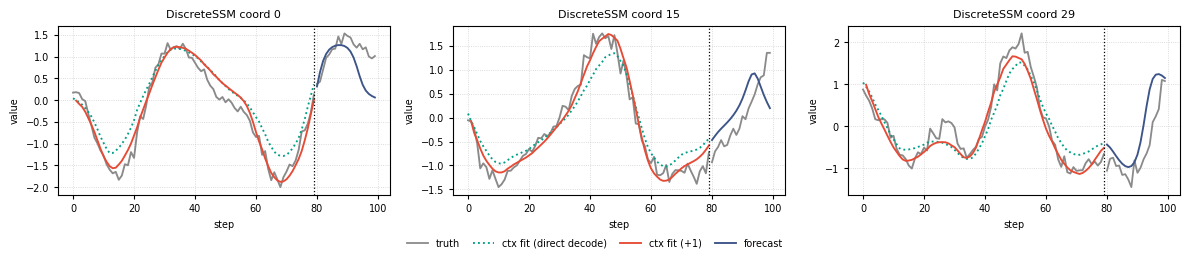

In [11]:
disc_module.eval()
disc_eval = evaluate_model_on_dataset_samples(disc_module, ds_test, latent_ds_test, n_plot=3)
plot_model_outputs('DiscreteSSM', disc_eval)


## 4. ODESSM: Train + Visualization


In [12]:
ode_train_loader = DataLoader(
    ds_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    num_workers=NUM_WORKERS,
    collate_fn=lambda batch: prepare_batched_traj(batch, cutoff_len=None),
)
ode_val_loader = DataLoader(
    ode_ds_val,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    num_workers=NUM_WORKERS,
    collate_fn=lambda batch: prepare_batched_traj(batch, cutoff_len=CONTEXT_LEN),
)
ode_test_loader = DataLoader(
    ode_ds_test,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    num_workers=NUM_WORKERS,
    collate_fn=lambda batch: prepare_batched_traj(batch, cutoff_len=CONTEXT_LEN),
)

ode_model_cfg = ODEModelConfig(
    dim_obs=OBS_DIM,
    dim_latent=LATENT_DIM,
    enc_rnn_hidden_dim=64,
    enc_rnn_num_layers=1,
    enc_proj_dim=64,
    ode_net_hidden_dim=[64, 64],
    dec_hidden_dim=[128, 64],
    x_sigma2=0.05,
    dropout=0.05,
    enc_direction='backward',
)
ode_opt_cfg = ODEOptConfig(
    n_epochs=120,
    batch_size=BATCH_SIZE,
    lr=5e-4,
    scheduler_type='MultiStepLR',
    milestones=[20, 40, 70],
    gamma=0.5,
    weight_decay=1e-6,
    loss_mode='iwae',
    loss_type='NLL',
    loss_reduction='mean',
    train_strategy='reconstruct',
    mc_samples=0,
    beta_max=1.0,
    warmup_epochs=8,
)
ode_module = ODESSM(ode_model_cfg, ode_opt_cfg)
ode_trainer = configure_trainer(
    ode_opt_cfg,
    gpu_id=GPU_ID if torch.cuda.is_available() else None,
    output_dir=OUTPUT_DIR / 'latent_ode',
    verbosity=10,
)
ode_trainer.fit(ode_module, train_dataloaders=ode_train_loader, val_dataloaders=ode_val_loader)


ODEModelConfig(dim_obs=30, dim_latent=5, enc_rnn_hidden_dim=64, enc_rnn_num_layers=1, enc_proj_dim=64, ode_net_hidden_dim=[64, 64], dec_hidden_dim=[128, 64], x_sigma2=0.05, dropout=0.05, enc_direction='backward')
----------------
ODEOptConfig(n_epochs=120, batch_size=128, lr=0.0005, scheduler_type='MultiStepLR', weight_decay=1e-06, check_val_every_n_epoch=1, gradient_clip_val=0.0, limit_val_batches=100, gradient_accumulation_steps=1, early_stopping=None, factor=None, patience=None, step_size=None, gamma=0.5, milestones=[20, 40, 70], loss_mode='iwae', loss_type='NLL', loss_reduction='mean', train_strategy='reconstruct', mc_samples=0, beta_max=1.0, warmup_epochs=8)


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]

  | Name     | Type           | Params | Mode 
----------------------------------------------------
0 | ode_loss | ODELoss        | 0      | train
1 | model    | LatentODEModel | 45.0 K | train
----------------------------------------------------
45.0 K    Trainable params
0         Non-trainable params
45.0 K    Total params
0.180     Total estimated model params size (MB)
33        Modules in train mode
0         Modules in eval mode


EPOCH=001 (timer=3s/epoch); train_loss=8.5099; val_loss=8.3465; lr=5.0E-04
    - train_err=8.50; val_err=8.34; train_kl=0.06; val_kl=0.06; 
EPOCH=010 (timer=4s/epoch); train_loss=2.5378; val_loss=1.9199; lr=5.0E-04
    - train_err=2.40; val_err=1.78; train_kl=0.14; val_kl=0.14; 
EPOCH=020 (timer=4s/epoch); train_loss=0.3451; val_loss=-0.1395; lr=2.5E-04
    - train_err=0.22; val_err=-0.27; train_kl=0.13; val_kl=0.13; 
EPOCH=030 (timer=4s/epoch); train_loss=-0.1892; val_loss=-0.5598; lr=2.5E-04
    - train_err=-0.31; val_err=-0.69; train_kl=0.12; val_kl=0.13; 
EPOCH=040 (timer=4s/epoch); train_loss=-0.4457; val_loss=-0.6805; lr=1.3E-04
    - train_err=-0.56; val_err=-0.80; train_kl=0.11; val_kl=0.12; 
EPOCH=050 (timer=4s/epoch); train_loss=-0.5362; val_loss=-0.7321; lr=1.3E-04
    - train_err=-0.65; val_err=-0.84; train_kl=0.11; val_kl=0.11; 
EPOCH=060 (timer=4s/epoch); train_loss=-0.6049; val_loss=-0.7926; lr=1.3E-04
    - train_err=-0.71; val_err=-0.90; train_kl=0.10; val_kl=0.11; 
EP

`Trainer.fit` stopped: `max_epochs=120` reached.


EPOCH=120 (timer=4s/epoch); train_loss=-0.7601; val_loss=-0.9063; lr=6.3E-05
    - train_err=-0.84; val_err=-0.99; train_kl=0.08; val_kl=0.09; 


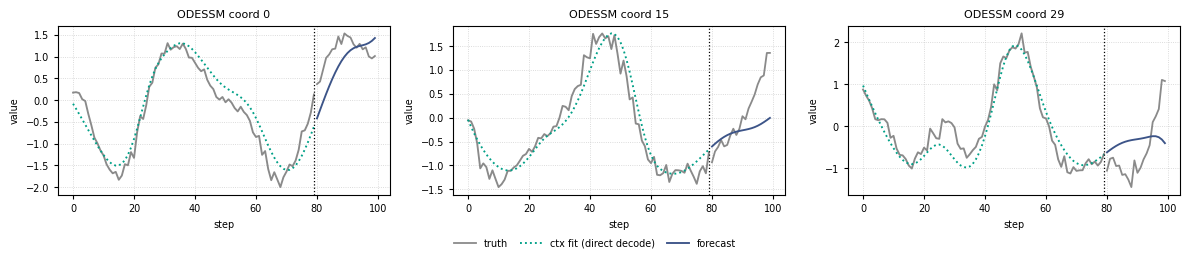

In [13]:
ode_module.eval()
ode_test_batch = next(iter(ode_test_loader))
ode_eval = evaluate_model_on_test_batch(ode_module, ode_test_batch, latent_ds_test, n_plot=3)
plot_model_outputs('ODESSM', ode_eval)


## 5. SDESSM: Train + Visualization


In [14]:
sde_train_loader = DataLoader(
    ds_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    num_workers=NUM_WORKERS,
)
sde_val_loader = DataLoader(
    ds_val,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    num_workers=NUM_WORKERS,
)

sde_model_cfg = SDEModelConfig(
    dim_obs=OBS_DIM,
    dim_latent=LATENT_DIM,
    enc_rnn_hidden_dim=64,
    enc_rnn_num_layers=1,
    enc_proj_dim=64,
    drift_net_hidden_dim=[64, 64],
    diffusion_net_hidden_dim=[64, 64],
    dec_hidden_dim=[128, 64],
    x_sigma2=0.05,
    dropout=0.05,
    z_sigma_type='diag',
    enc_direction='backward',
)
sde_opt_cfg = SDEOptConfig(
    n_epochs=50,
    batch_size=BATCH_SIZE,
    lr=5e-4,
    scheduler_type='MultiStepLR',
    milestones=[20, 40],
    gamma=0.5,
    weight_decay=1e-6,
    loss_type='NLL',
    loss_reduction='mean',
    kl_mode='exact',
    mc_samples=0,
    beta_max=1.0,
    warmup_epochs=8,
)
sde_module = SDESSM(sde_model_cfg, sde_opt_cfg)
sde_trainer = configure_trainer(
    sde_opt_cfg,
    gpu_id=GPU_ID if torch.cuda.is_available() else None,
    output_dir=OUTPUT_DIR / 'latent_sde',
    verbosity=10,
)
sde_trainer.fit(sde_module, train_dataloaders=sde_train_loader, val_dataloaders=sde_val_loader)


SDEModelConfig(dim_obs=30, dim_latent=5, enc_rnn_hidden_dim=64, enc_rnn_num_layers=1, enc_proj_dim=64, drift_net_hidden_dim=[64, 64], diffusion_net_hidden_dim=[64, 64], dec_hidden_dim=[128, 64], x_sigma2=0.05, dropout=0.05, z_sigma_type='diag', enc_direction='backward')
----------------
SDEOptConfig(n_epochs=50, batch_size=128, lr=0.0005, scheduler_type='MultiStepLR', weight_decay=1e-06, check_val_every_n_epoch=1, gradient_clip_val=0.0, limit_val_batches=100, gradient_accumulation_steps=1, early_stopping=None, factor=None, patience=None, step_size=None, gamma=0.5, milestones=[20, 40], loss_type='NLL', loss_reduction='mean', train_strategy='reconstruct', kl_mode='exact', mc_samples=0, beta_max=1.0, warmup_epochs=8)


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]

  | Name  | Type           | Params | Mode 
-------------------------------------------------
0 | elbo  | SDEELBO        | 0      | train
1 | model | LatentSDEModel | 50.0 K | train
-------------------------------------------------
50.0 K    Trainable params
0         Non-trainable params
50.0 K    Total params
0.200     Total estimated model params size (MB)
48        Modules in train mode
0         Modules in eval mode


EPOCH=001 (timer=1s/epoch); train_loss=15.0291; val_loss=11.1773; lr=5.0E-04
    - train_err=8.45; val_err=8.26; train_kl=52.64; val_kl=23.30; 
EPOCH=010 (timer=2s/epoch); train_loss=0.3593; val_loss=-0.3476; lr=5.0E-04
    - train_err=-0.06; val_err=-0.42; train_kl=0.42; val_kl=0.07; 
EPOCH=020 (timer=2s/epoch); train_loss=-0.5142; val_loss=-0.8771; lr=2.5E-04
    - train_err=-0.81; val_err=-0.90; train_kl=0.29; val_kl=0.03; 
EPOCH=030 (timer=2s/epoch); train_loss=-0.5917; val_loss=-0.9143; lr=2.5E-04
    - train_err=-0.86; val_err=-0.94; train_kl=0.27; val_kl=0.02; 
EPOCH=040 (timer=2s/epoch); train_loss=-0.6349; val_loss=-0.9334; lr=1.3E-04
    - train_err=-0.89; val_err=-0.95; train_kl=0.25; val_kl=0.02; 


`Trainer.fit` stopped: `max_epochs=50` reached.


EPOCH=050 (timer=2s/epoch); train_loss=-0.6582; val_loss=-0.9470; lr=1.3E-04
    - train_err=-0.90; val_err=-0.97; train_kl=0.25; val_kl=0.02; 


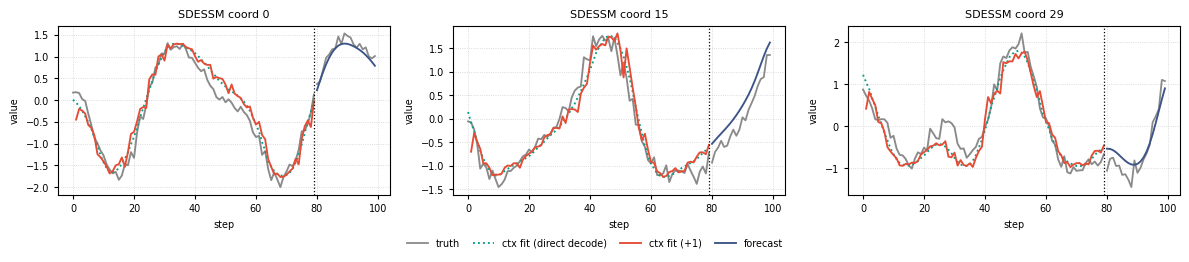

In [15]:
sde_module.eval()
sde_eval = evaluate_model_on_dataset_samples(sde_module, ds_test, latent_ds_test, n_plot=3)
plot_model_outputs('SDESSM', sde_eval)


## 6. Remark: Latent State Identifiability

The observation plots above use the model outputs directly. For the latent state, the learned coordinates are only identifiable up to an invertible linear transform, so we first show the raw inferred latents against the simulator truth and then an aligned version used only for visualization.

In [16]:
def fit_linear_alignment(inferred_latent, true_latent):
    x = inferred_latent.reshape(-1, inferred_latent.shape[-1]).astype(np.float64)
    y = true_latent.reshape(-1, true_latent.shape[-1]).astype(np.float64)
    x_mean = x.mean(axis=0, keepdims=True)
    y_mean = y.mean(axis=0, keepdims=True)
    x_c = x - x_mean
    y_c = y - y_mean

    u, _, vt = np.linalg.svd(x_c.T @ y_c, full_matrices=False)
    r = u @ vt

    x_r = x_c @ r
    gain = float((x_r * y_c).sum() / ((x_r * x_r).sum() + 1e-12))
    b = y_mean - gain * x_mean @ r

    return {
        'r': r.astype(np.float32),
        'gain': np.float32(gain),
        'b': b.astype(np.float32),
    }


def apply_alignment(latent, align):
    z = to_np(latent)
    return (align['gain'] * (z @ align['r']) + align['b']).astype(np.float32)


def fit_alignment_for_model(lightning_module, obs_dataset, latent_dataset, max_windows=1024):
    n_samples = min(max_windows, len(obs_dataset), len(latent_dataset))
    pred_all = []
    true_all = []

    with torch.no_grad():
        for idx in range(n_samples):
            obs_sample = sample_to_device(obs_dataset[idx], lightning_module.device)
            latent_sample = latent_dataset[idx]
            z_ctx = infer_context_latent_from_sample(lightning_module, obs_sample)
            pred_all.append(to_np(z_ctx))
            true_all.append(to_np(latent_sample['x_traj']))

    pred_cat = np.stack(pred_all, axis=0)
    true_cat = np.stack(true_all, axis=0)
    return fit_linear_alignment(pred_cat, true_cat)


def plot_latent_identifiability(title_prefix, eval_list, align=None):
    sample = eval_list[0]
    ctx_idx = np.arange(sample['z_ctx_true'].shape[0])
    pred_idx = np.arange(sample['z_ctx_true'].shape[0], sample['z_ctx_true'].shape[0] + sample['z_fut_true'].shape[0])
    if align is None:
        z_ctx_plot = sample['z_ctx']
        z_fut_plot = sample['z_fut_pred']
        ctx_label = 'raw ctx'
        fut_label = 'raw forecast'
        suffix = 'unaligned'
    else:
        z_ctx_plot = apply_alignment(sample['z_ctx'], align)
        z_fut_plot = apply_alignment(sample['z_fut_pred'], align)
        ctx_label = 'aligned ctx'
        fut_label = 'aligned forecast'
        suffix = 'aligned'

    fig, axes = plt.subplots(1, len(LATENT_DIMS_TO_PLOT), figsize=(4 * len(LATENT_DIMS_TO_PLOT), 2.5))
    if len(LATENT_DIMS_TO_PLOT) == 1:
        axes = [axes]
    for ax, d in zip(axes, LATENT_DIMS_TO_PLOT):
        ax.plot(ctx_idx, sample['z_ctx_true'][:, d], color=PLOT_COLORS['latent_true'], lw=1.3, label='truth')
        ax.plot(ctx_idx, z_ctx_plot[:, d], color=PLOT_COLORS['latent_ctx'], lw=1.3, label=ctx_label)
        ax.plot(pred_idx, sample['z_fut_true'][:, d], color=PLOT_COLORS['future_truth'], linestyle='-', lw=1.25, label='truth')
        ax.plot(pred_idx, z_fut_plot[:, d], color=PLOT_COLORS['latent_forecast'], lw=1.3, linestyle='-', label=fut_label)
        ax.axvline(sample['z_ctx_true'].shape[0] - 1, color='black', linestyle=':', linewidth=0.9)
        ax.set_title(f'{title_prefix} latent dim {d} ({suffix})', fontsize=8)
        ax.set_xlabel('step', fontsize=7)
        ax.set_ylabel('latent value', fontsize=7)
        ax.tick_params(axis='both', labelsize=7, length=3.0, width=0.8)
        ax.grid(linestyle=':', linewidth=0.6, alpha=0.7, color=PLOT_COLORS['grid'])
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_color('black')
            spine.set_linewidth(0.8)
    handles, labels = axes[0].get_legend_handles_labels()
    dedup = dict(zip(labels, handles))
    fig.legend(
        dedup.values(),
        dedup.keys(),
        loc='lower center',
        bbox_to_anchor=(0.5, -0.05),
        ncol=3,
        fontsize=7,
        frameon=False,
        handlelength=2.2,
        columnspacing=1.3,
    )
    plt.tight_layout(rect=(0, 0.13, 1, 1))


disc_align = fit_alignment_for_model(disc_module, ds_train, latent_ds_train, max_windows=800)
ode_align = fit_alignment_for_model(ode_module, ds_train, latent_ds_train, max_windows=800)
sde_align = fit_alignment_for_model(sde_module, ds_train, latent_ds_train, max_windows=800)


### Raw Latent vs Truth

These panels use the inferred latent states exactly as returned by each model.

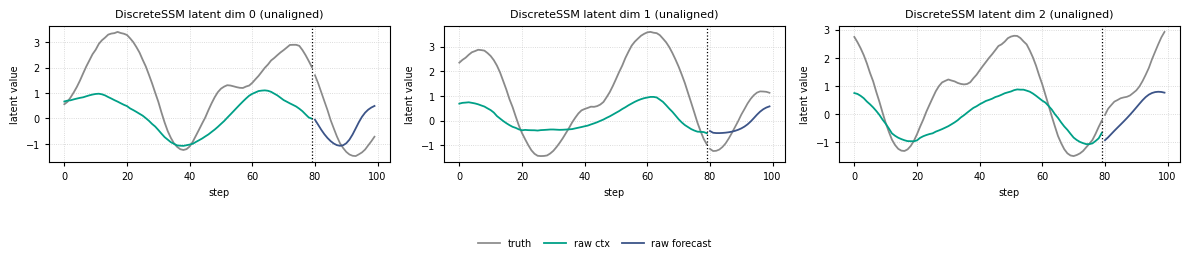

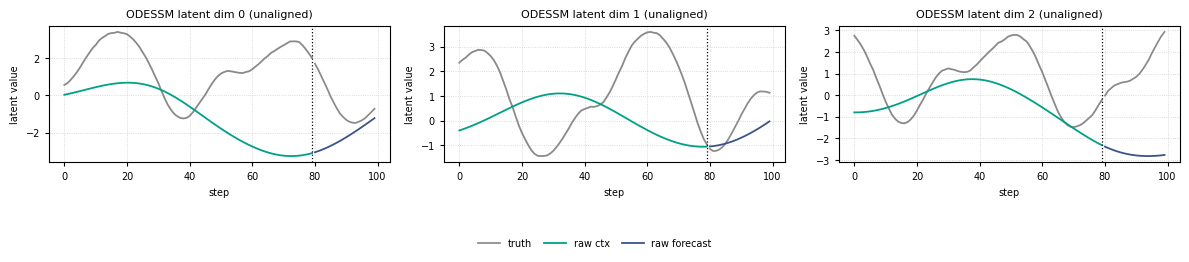

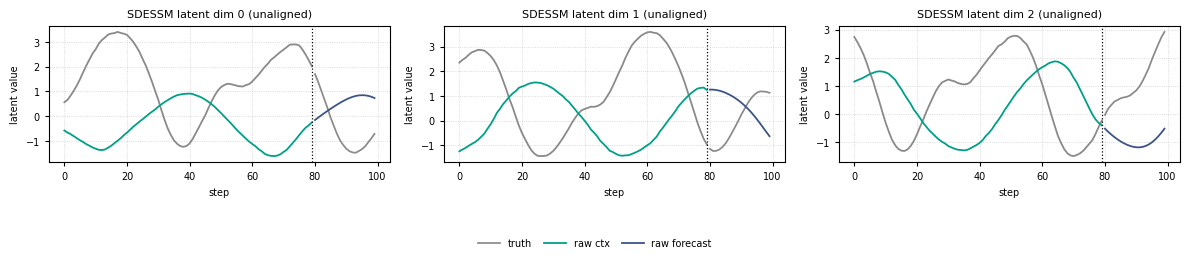

In [17]:
plot_latent_identifiability('DiscreteSSM', disc_eval, align=None)
plot_latent_identifiability('ODESSM', ode_eval, align=None)
plot_latent_identifiability('SDESSM', sde_eval, align=None)


### Aligned Latent vs Truth

Here we fit a linear alignment on training-context latent windows and apply it only for visualization.

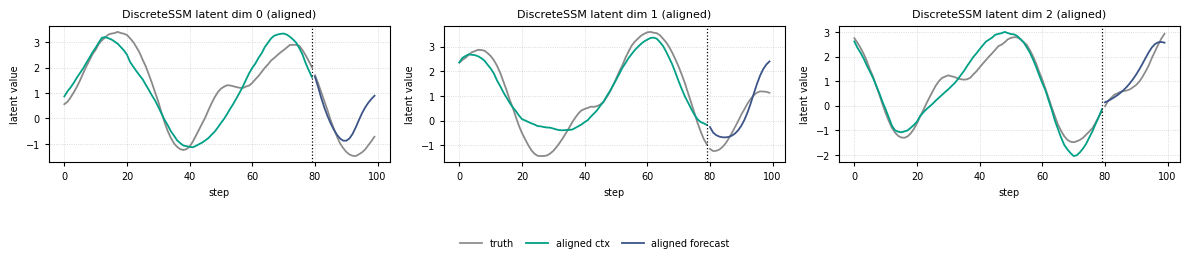

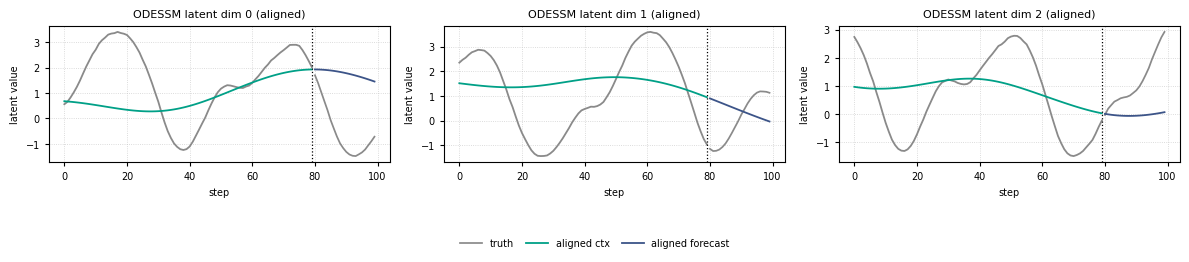

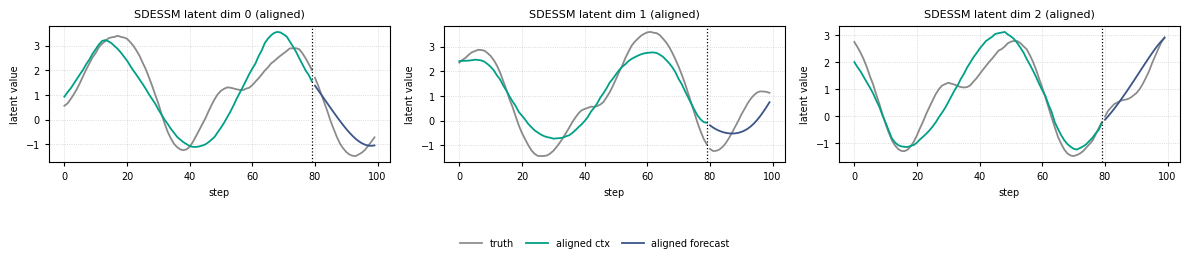

In [18]:
plot_latent_identifiability('DiscreteSSM', disc_eval, align=disc_align)
plot_latent_identifiability('ODESSM', ode_eval, align=ode_align)
plot_latent_identifiability('SDESSM', sde_eval, align=sde_align)
